# 03 · Copy-mutate baselines and category fingerprints

How much of a real cuisine does a simple model of culinary evolution reproduce? The copy-mutate model is the evolutionary baseline of the D2 audit. An LLM that claims to know a cuisine should do at least as well.

**Copy-mutate** (Kinouchi et al. 2008; Jain & Bagler 2018; Tuwani et al. 2019, Algorithm 1), as implemented in `flavoraudit.evolution`:
- It starts from m = 20 of the cuisine's ingredients and n = m/φ random recipes, where φ is the cuisine's ratio of distinct ingredients to recipes.
- Each new recipe copies a random existing recipe and attempts M = 4 replacements. A replacement is kept when the new ingredient has higher *fitness*.
- A new ingredient joins the pool whenever the pool-to-recipe ratio falls below φ.
- **Fitness** is either *random*, drawn from U(0, 1) as in Kinouchi 2008 and Tuwani 2019, or *ranked*, the ingredient's real frequency (Jain & Bagler 2018's "CM-fitness ranked").

**What we compare** with the real cuisine (Korea, the running example of notebook 01):
1. the frequency-rank curve of ingredient popularity, with its mean absolute error (Tuwani et al. 2019);
2. the **category fingerprint**: for each ingredient category, ΔNs_cat and Z_cat against a null that re-draws only that category's ingredients in every recipe (Jain, Rakhi & Bagler 2015);
3. which ingredients are used (prevalence JSD) and the food-pairing Z.

A control shows how much a genuine cuisine of the same size varies: bootstrap resamples of the real recipes.

Copy-mutate and these metrics are published methods (copy-mutate was also our course assignment A3). They serve here as a baseline, not a contribution. **Run time: under a minute.**

In [1]:
import time
import zlib
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import flavoraudit as fa
from flavoraudit.composition import frequency_rank, frequency_rank_mae, prevalence_jsd
from flavoraudit.evolution import copy_mutate_with_stats
from flavoraudit.pairing import Cuisine

# The repository root: the first folder upwards whose data/raw holds the source databases.
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data" / "raw" / "culinarydb").is_dir())
REGION, N_INSTANCES = "Korea", 10
REAL_COLOR, CM_COLOR = "#000000", "#999999"  # the project palette (configs/models.yaml): real, copy-mutate

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
print(f"flavoraudit {fa.__version__}")

flavoraudit 0.1.0.dev0


In [2]:
world = fa.load_world(REPO / "data" / "raw")
real = world.cuisine(REGION)
n_ingredients = len(real.pool()[0])
print(
    f"{REGION}: {len(real)} recipes, {n_ingredients} distinct ingredients (φ = {n_ingredients / len(real):.3f}), "
    f"{real.sizes.mean():.2f} ingredients per recipe"
)

Korea: 301 recipes, 199 distinct ingredients (φ = 0.661), 9.33 ingredients per recipe


## One copy-mutate run

The seeds follow `analysis/audit/copy_mutate_baseline.py`, so these are exactly the D2 baseline cuisines for Korea. `sizes="empirical"` draws the seed recipes' sizes from the real size distribution, which is the D2 setting; the papers use one mean size (`sizes="mean"`). The run statistics include:
- `acceptance_rate`: the share of attempted replacements that were kept;
- `duplicate_share`: the share of recipes that are identical copies (the papers keep them too).

In [3]:
def d2_seed(fitness: str, instance: int) -> int:
    # Seed of one instance in analysis/audit/copy_mutate_baseline.py (base seed 0; ranked = model 0, random = 1).
    model = ("ranked", "random").index(fitness)
    return int(np.random.SeedSequence([0, zlib.crc32(REGION.encode()), model, instance]).generate_state(1)[0])


cm, run_stats = copy_mutate_with_stats(real, fitness="ranked", sizes="empirical", seed=d2_seed("ranked", 0))
pd.Series(run_stats).to_frame(f"{REGION}: CM-R, ranked fitness, instance 0")

,"Korea: CM-R, ranked fitness, instance 0"
variant,CM-R
fitness,ranked
mutations_per_copy,4
phi,0.66113
seed_ingredients,20
seed_recipes,30
final_pool,199
mutation_attempts,1084
mutations_accepted,324
acceptance_rate,0.298893


In [4]:
t0 = time.perf_counter()
rng = np.random.default_rng(0)
cuisines = {
    "real, bootstrap resample": [
        Cuisine(f"{REGION}:bootstrap", [real.recipes[i] for i in rng.choice(len(real), len(real))], real.categories)
        for _ in range(N_INSTANCES)
    ],
    **{
        f"copy-mutate, {fitness} fitness": [
            fa.copy_mutate(real, fitness=fitness, sizes="empirical", seed=d2_seed(fitness, k))
            for k in range(N_INSTANCES)
        ]
        for fitness in ("ranked", "random")
    },
}
print(f"{N_INSTANCES} cuisines of {len(real)} recipes per source in {time.perf_counter() - t0:.1f} s")

10 cuisines of 301 recipes per source in 0.1 s


## Ingredient popularity: the frequency-rank curve

Rank the ingredients by how many recipes use them and divide by the top ingredient's count. Tuwani et al. (2019) compare these curves by their mean absolute error over the common ranks (`frequency_rank_mae`).

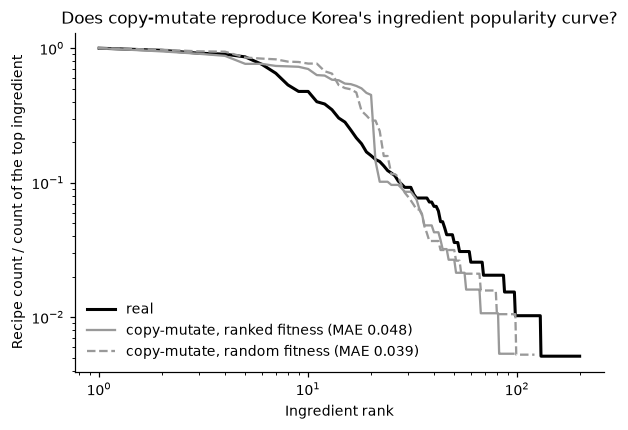

In [5]:
fig, ax = plt.subplots(figsize=(6.2, 4))
curves = [
    ("real", real, {"color": REAL_COLOR, "lw": 2}),
    ("copy-mutate, ranked fitness", cuisines["copy-mutate, ranked fitness"][0], {"color": CM_COLOR}),
    ("copy-mutate, random fitness", cuisines["copy-mutate, random fitness"][0], {"color": CM_COLOR, "ls": "--"}),
]
for label, cuisine, style in curves:
    f = frequency_rank(cuisine)
    mae = "" if cuisine is real else f" (MAE {frequency_rank_mae(cuisine, real):.3f})"
    ax.loglog(np.arange(1, len(f) + 1), f, label=label + mae, **style)
ax.set(xlabel="Ingredient rank", ylabel="Recipe count / count of the top ingredient")
ax.set_title(f"Does copy-mutate reproduce {REGION}'s ingredient popularity curve?")
ax.legend(frameon=False)
plt.show()

## The category fingerprint

For each category with at least 20 recipes, `fingerprint` re-draws only that category's ingredients in every recipe that contains it, and it keeps the rest of the recipe. It returns ΔNs_cat and Z_cat. A positive Z_cat means that the category's ingredients share more flavor compounds with the rest of the recipe than random picks from the same category would. "The pattern of category contributions presents itself as a 'culinary fingerprint' of the cuisine" (Jain, Rakhi & Bagler 2015).

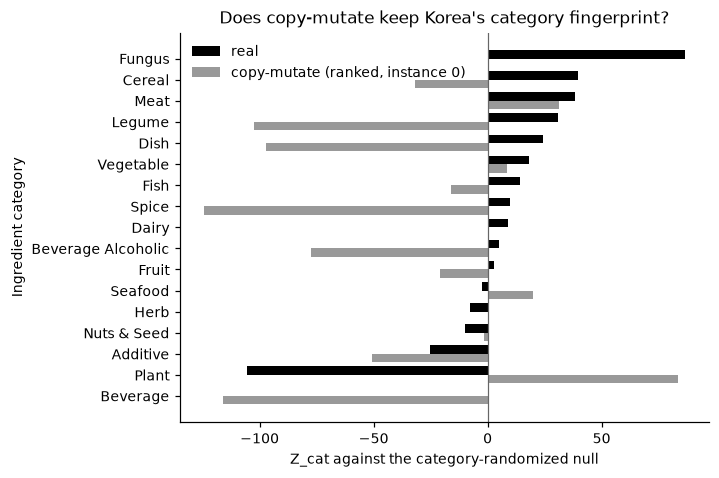

Fingerprint similarity, copy-mutate vs real over 13 shared categories: Spearman -0.27, cosine -0.49


In [6]:
fp_real = fa.fingerprint(real, world.S, n_null=20_000, seed=0)
fp_cm = fa.fingerprint(cuisines["copy-mutate, ranked fitness"][0], world.S, n_null=20_000, seed=0)
both = pd.concat({"real": fp_real["z_cat"], "copy-mutate": fp_cm["z_cat"]}, axis=1)  # NaN: category not scored
both = both.sort_values("real", na_position="first")

fig, ax = plt.subplots(figsize=(6.2, 4.6))
y = np.arange(len(both))
ax.barh(y + 0.2, both["real"], height=0.4, color=REAL_COLOR, label="real")
ax.barh(y - 0.2, both["copy-mutate"], height=0.4, color=CM_COLOR, label="copy-mutate (ranked, instance 0)")
ax.axvline(0, color="0.4", lw=0.8)
ax.set_yticks(y, both.index)
ax.set(xlabel="Z_cat against the category-randomized null", ylabel="Ingredient category")
ax.set_title(f"Does copy-mutate keep {REGION}'s category fingerprint?")
ax.legend(frameon=False, loc="upper left")
plt.show()
sim = fa.fingerprint_similarity(fp_cm, fp_real)
print(
    f"Fingerprint similarity, copy-mutate vs real over {sim['n_categories']} shared categories: "
    f"Spearman {sim['spearman']:.2f}, cosine {sim['cosine']:.2f}"
)

## All instances against the real cuisine

Each source has 10 instances. The columns are:
- frequency-rank MAE and prevalence JSD against the real cuisine;
- the number of distinct ingredients used;
- the food-pairing Z (random null, 20,000 recipes) and how many instances keep the real cuisine's sign;
- the fingerprint Spearman ρ against the real fingerprint, computed with the scorecard's settings (5,000 null recipes per category; categories in ≥ 10 recipes).

The bootstrap rows show the sampling noise of a genuine cuisine of the same size. The MAE and JSD of the copy-mutate instances equal those in the D2 baseline scorecard for Korea, because the cuisines are the same. Z and the fingerprints use this notebook's own Monte-Carlo seeds.

In [7]:
t0 = time.perf_counter()
z_real = fa.food_pairing(real, world.S, n_null=20_000, seed=0).z_sb
rows = []
for source, instances in cuisines.items():
    for k, c in enumerate(instances):
        fp = fa.fingerprint(c, world.S, n_null=5_000, seed=k, min_recipes=10)
        rows.append(
            {
                "source": source,
                "freq_rank_mae": frequency_rank_mae(c, real),
                "prevalence_jsd": prevalence_jsd(c, real),
                "ingredients_used": len(c.pool()[0]),
                "z": fa.food_pairing(c, world.S, n_null=20_000, seed=k).z_sb,
                "fingerprint_rho": fa.fingerprint_similarity(fp, fp_real)["spearman"],
            }
        )
runs = pd.DataFrame(rows)
runs["same_sign_as_real"] = np.sign(runs["z"]) == np.sign(z_real)


def mean_sd(values: pd.Series, digits: int = 3) -> str:
    return f"{values.mean():.{digits}f} ± {values.std(ddof=1):.{digits}f}"


summary = runs.groupby("source", sort=False).agg(
    freq_rank_mae=("freq_rank_mae", mean_sd),
    prevalence_jsd=("prevalence_jsd", mean_sd),
    ingredients_used=("ingredients_used", lambda v: mean_sd(v, 0)),
    z=("z", lambda v: mean_sd(v, 1)),
    same_sign_as_real=("same_sign_as_real", lambda v: f"{v.sum()}/{len(v)}"),
    fingerprint_rho=("fingerprint_rho", lambda v: mean_sd(v, 2)),
)
print(f"Real {REGION}: Z = {z_real:.1f}, {n_ingredients} ingredients ({time.perf_counter() - t0:.0f} s)")
summary

Real Korea: Z = -52.9, 199 ingredients (10 s)


,freq_rank_mae,prevalence_jsd,ingredients_used,z,same_sign_as_real,fingerprint_rho
source,,,,,,
"real, bootstrap resample",0.006 ± 0.001,0.015 ± 0.001,166 ± 5,-65.7 ± 29.1,10/10,0.80 ± 0.09
"copy-mutate, ranked fitness",0.045 ± 0.009,0.616 ± 0.029,97 ± 12,6.2 ± 186.1,4/10,-0.02 ± 0.36
"copy-mutate, random fitness",0.032 ± 0.004,0.686 ± 0.045,118 ± 8,18.0 ± 125.5,5/10,0.12 ± 0.30


**What the table shows** (Korea only; `analysis/audit/copy_mutate_baseline.py` runs all 22 regions):
- **Popularity curve.** Both fitness rules produce a heavy-tailed popularity curve with an MAE of a few hundredths, comparable to the fits that Tuwani et al. (2019) report. Random fitness fits the curve at least as well as ranked fitness. Both MAEs are still several times that of a genuine resample. A matching curve is therefore a weak test of a cuisine's identity.
- **Which ingredients.** Ranked fitness rewards the cuisine's popular ingredients, so its ingredient usage is closer to the real cuisine (lower JSD) than with random fitness. Both stay far from the bootstrap noise level, and both use fewer distinct ingredients than a genuine resample.
- **Food pairing and fingerprint.** Neither rule controls them. Z swings widely between instances and has the real cuisine's sign in only about half of them, and the fingerprint correlation is near zero. Bootstrap resamples keep both: the same sign every time and a high fingerprint correlation.

This is why the D2 scorecard reports pairing, fingerprint, composition and popularity metrics side by side. An LLM cuisine is judged against both the real-sample noise level and this baseline.